# Tema 30 · Proyecto final e IA responsable

Construir un sistema de IA completo, medirlo con honestidad y pensar en sus efectos.

Este cuaderno es el tema 30 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/30-proyecto-final-e-ia-responsable/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

Imagina que un banco usa un modelo para decidir a quién le ofrece una tarjeta de crédito. El modelo aprendió de miles de ejemplos y acierta 87 de cada 100 veces. ¿Es un buen modelo?

Con lo que sabes desde el tema 9, ya desconfías de un solo número: hay que mirar qué errores comete. Este tema agrega una pregunta más: **¿se equivoca igual con todas las personas?** Un modelo puede tener muy buena exactitud y, aun así, rechazar con mucha más frecuencia a las mujeres que sí cumplían, o a las personas de un grupo que casi no aparecía en los datos. Esos errores no los paga el modelo, los pagan las personas.

Este es el último tema de la ruta. Vas a juntar todo lo que aprendiste en un **proyecto completo**, medido con honestidad, y a pensar en sus efectos. En este tema vas a:

- recorrer el ciclo de un proyecto: **pregunta, datos, línea base, iteración y evaluación final**;
- **auditar un modelo por subgrupos** con `pandas.groupby`, con intervalos de **bootstrap** para saber si una diferencia es real;
- medir la **equidad** con dos métricas, la **paridad demográfica** y la **igualdad de oportunidades**, y ver por qué, cuando los grupos son distintos, no se pueden igualar todas las métricas a la vez;
- documentar un modelo con una **ficha de modelo** y planificar tu **proyecto final** con una plantilla;
- argumentar con ejemplos concretos los riesgos de **privacidad**, sesgo, mal uso e **impacto ambiental**, y conocer qué dice hoy la normativa de Bolivia.

Necesitas las métricas del tema 9 (matriz de confusión, exhaustividad, umbral), el `Pipeline` del tema 10 y la importancia por permutación del tema 11.

## Actividad: umbrales justos

Cuarenta personas del grupo A y cuarenta del grupo B piden un préstamo. Un modelo le da a cada una un puntaje entre 0 y 1, y cada grupo tiene su propio **umbral**: quien queda a su derecha es aprobado. Las figuras **rellenas** son las personas que sí habrían devuelto el préstamo; las **huecas**, las que no. El grupo A se dibuja con círculos y el B con cuadrados más claros. Los datos son **sintéticos**: los inventamos para que los dos grupos tengan distribuciones distintas, como pasa a menudo con datos reales. En el grupo A la mitad habría devuelto el préstamo; en el grupo B, solo una de cada cuatro, y el modelo le da puntajes más bajos.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/30-proyecto-final-e-ia-responsable/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Con los dos umbrales en 0,5, mira la tabla. ¿Qué parte de cada grupo es aprobada? De quienes sí lo habrían devuelto, ¿qué parte es aprobada en cada grupo? Esa segunda tasa es la **tasa de verdaderos positivos** (TVP), la exhaustividad del tema 9 calculada dentro de cada grupo.
2. Pulsa «Igualar aprobación». El umbral de B baja hasta que su tasa de aprobación queda lo más cerca posible de la de A. ¿Qué pasó con la TVP de B y con la exactitud global?
3. Pulsa «Igualar oportunidades». Ahora el umbral de B se elige para que su TVP sea igual a la de A. ¿Las tasas de aprobación quedaron iguales?
4. Mueve los dos umbrales como quieras e intenta igualar al mismo tiempo la aprobación y la TVP sin que la exactitud se caiga. ¿Lo consigues?

Lo que acabas de ver es el centro del tema: **cuando los grupos son distintos en los datos, no se pueden igualar todas las métricas a la vez**. Igualar la aprobación obliga a aprobar a más personas de B que no lo habrían devuelto; igualar las oportunidades deja tasas de aprobación distintas. Con un umbral por grupo, la aprobación y la TVP solo quedan iguales en los extremos (aprobar a casi todos o a casi nadie), donde la exactitud se desploma. Y aunque eligieras persona por persona a quién aprobar, podrías igualar la aprobación y la TVP, pero a costa de aprobar a muchos más negativos de B: su tasa de falsos positivos (TFP) quedaría distinta de la de A. Hay que **elegir** qué significa «justo» en cada problema y **justificarlo**. El resto del tema hace lo mismo con datos reales.

## El ciclo de un proyecto

Todos los temas de la ruta siguieron, sin decirlo, el mismo camino. Ahora le ponemos nombre, porque es el que vas a seguir en tu proyecto final:

1. **La pregunta.** Qué quieres predecir o descubrir, para quién y qué decisión se tomará con la respuesta. Una buena pregunta dice también qué error cuesta más (tema 9).
2. **Los datos.** De dónde vienen, con qué licencia, cuántos son, quién aparece y quién falta. Se dividen **antes** de mirar demasiado: entrenamiento, validación y prueba (tema 7).
3. **La línea base.** El modelo más simple posible: predecir siempre la clase más frecuente, el promedio, o «mañana igual que hoy» (tema 13). Todo modelo tiene que ganarle; si no, algo anda mal.
4. **Iterar.** Probar modelos y variables midiendo en validación, y anotar cada intento en una bitácora: qué cambiaste y qué pasó.
5. **La evaluación final.** Una sola vez, con el conjunto de prueba, cuando ya no vas a cambiar nada (temas 7 y 10). Aquí se agrega el **análisis por subgrupos** y la **ficha del modelo**.

**¿Qué modelo elegir?** Depende de los datos y de la máquina que tengas:

- **Tablas** con columnas de números y categorías: los modelos clásicos, sobre todo los árboles con boosting (tema 11), suelen ganar y entrenan en segundos.
- **Texto, imágenes o audio con pocos ejemplos**: un modelo **preentrenado** que solo se ajusta (temas 25 y 26). Entrenar desde cero una red grande con pocos datos casi nunca funciona.
- **Entrenar desde cero** (temas 18 a 20) tiene sentido cuando los datos son muchos y muy distintos de los que vio cualquier modelo preentrenado, o cuando el modelo es pequeño.

**Con poca máquina**, que es lo normal en Colab sin GPU: empieza con una muestra pequeña de los datos para depurar el código, mide cuánto tarda cada paso con `time.perf_counter()`, guarda los resultados intermedios y solo al final entrena con todo. Un modelo que entrena en dos minutos te deja probar treinta ideas en una tarde; uno que tarda una hora, cuatro.

## Los datos: un censo de 1994

Vamos a auditar un modelo entrenado con **Adult** (también llamado *Census Income*), uno de los datasets más usados para enseñar este tema. Tiene 48 842 personas del censo de los Estados Unidos de 1994 y la tarea es predecir si una persona ganaba **más de 50 000 dólares al año**. Lo publicaron Barry Becker y Ronny Kohavi en el [repositorio UCI](https://archive.ics.uci.edu/dataset/2/adult) (DOI 10.24432/C5XW20) con licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), que permite usarlo citando a sus autores; aquí se descarga desde OpenML (dataset 1590).

Antes de usarlo, tres advertencias que van en cualquier informe serio:

- Son datos de **otro país y de hace más de 30 años**. El umbral de 50 000 dólares no se ajustó por inflación. Un equipo de investigadores mostró sus límites y propuso datos más nuevos del mismo censo ([Ding y otros, 2021](https://arxiv.org/abs/2108.04884)). Lo usamos porque es pequeño, está bien documentado y sirve para aprender a auditar, **no** para decidir nada sobre personas reales.
- La columna de sexo tiene solo dos valores, los que registró el censo de entonces. No describe a todas las personas.
- El «banco» de este tema es imaginario: llamamos **aprobar** a que el modelo prediga «más de 50 000», para pensar en un uso concreto.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

# La primera vez se descarga (unos 4 MB); después sale de la caché
adult = fetch_openml("adult", version=2, as_frame=True).frame

# Nombres en español; se dejan fuera fnlwgt (un peso de muestreo
# del censo) y education (repite anios_estudio en palabras)
datos = adult.rename(columns={
    "age": "edad", "workclass": "empleador",
    "education-num": "anios_estudio", "marital-status": "estado_civil",
    "occupation": "ocupacion", "relationship": "parentesco",
    "capital-gain": "ganancia_capital", "capital-loss": "perdida_capital",
    "hours-per-week": "horas", "native-country": "pais", "race": "raza",
}).drop(columns=["fnlwgt", "education"])
sexos = {"Female": "mujer", "Male": "hombre"}
datos["sexo"] = datos["sex"].astype(str).map(sexos)
datos["ingreso_alto"] = (datos["class"] == ">50K").astype(int)
datos = datos.drop(columns=["sex", "class"])

print(datos.shape)
print(f"Ganan más de 50 000 dólares: {datos['ingreso_alto'].mean():.1%}")
# tasa_base: la fracción del grupo que realmente es positiva
print(datos.groupby("sexo")["ingreso_alto"]
      .agg(personas="size", tasa_base="mean").round(3))

(48842, 13)
Ganan más de 50 000 dólares: 23.9%
        personas  tasa_base
sexo                       
hombre     32650      0.304
mujer      16192      0.109


En estos datos, el 30,4 % de los hombres y solo el 10,9 % de las mujeres ganaban más de 50 000 dólares. Esa diferencia **no dice nada sobre la capacidad de nadie**: refleja cómo era el mercado de trabajo en 1994. Influyen la brecha salarial entre hombres y mujeres por el mismo trabajo, que más mujeres trabajaran a tiempo parcial o se ocuparan del cuidado de la familia sin sueldo, y que algunas ocupaciones mejor pagadas estuvieran casi cerradas para ellas. Los datos son un registro de esas **desigualdades históricas**, y un modelo que aprende de ellos aprende a repetirlas. Por eso los **atributos sensibles**, como el sexo, el origen étnico, la religión, la edad o una discapacidad, se tratan con cuidado: no para adivinar cosas sobre una persona, sino para **revisar** si el modelo trata peor a algún grupo. La edad también es sensible; aquí la dejamos como variable porque se relaciona con la experiencia laboral, pero también habría que auditar el modelo por edad (puedes hacerlo como ejercicio extra).

## Borrar una columna no basta

Dividimos en tres partes: **entrenamiento** (60 %), **validación** (20 %) para elegir el modelo y los umbrales, y **prueba** (20 %), que se usa una sola vez al final. Como queremos medir por grupos, estratificamos por la combinación de ingreso y sexo: así cada parte tiene la misma proporción de mujeres con ingreso alto, que son pocas.

Una idea muy común es «si el modelo no ve el sexo, no puede discriminar». Por eso dejamos fuera las columnas `sexo` y `raza` de las variables del modelo, pero las guardamos aparte para la auditoría. Veamos si eso alcanza.

In [ ]:
from sklearn.model_selection import train_test_split

NUMERICAS = ["edad", "anios_estudio", "ganancia_capital",
             "perdida_capital", "horas"]
CATEGORICAS = ["empleador", "estado_civil", "ocupacion", "parentesco",
               "pais"]
X = datos[NUMERICAS + CATEGORICAS]
y = datos["ingreso_alto"]
sexo = datos["sexo"]

# Se estratifica por ingreso y sexo a la vez: las tres partes tienen
# las mismas proporciones de cada combinación
estratos = y.astype(str) + sexo
X_ent, X_resto, y_ent, y_resto, s_ent, s_resto = train_test_split(
    X, y, sexo, test_size=0.4, stratify=estratos, random_state=0)
X_val, X_pru, y_val, y_pru, s_val, s_pru = train_test_split(
    X_resto, y_resto, s_resto, test_size=0.5,
    stratify=estratos[X_resto.index], random_state=0)
print(f"Entrenamiento: {len(X_ent)}   validación: {len(X_val)}"
      f"   prueba: {len(X_pru)}")

# ¿Quitar la columna sexo basta para que el modelo no la vea?
print(pd.crosstab(datos["parentesco"], datos["sexo"]))

Entrenamiento: 29305   validación: 9768   prueba: 9769
sexo            hombre  mujer
parentesco                   
Husband          19715      1
Not-in-family     6713   5870
Other-relative     817    689
Own-child         4205   3376
Unmarried         1197   3928
Wife                 3   2328


No alcanza. La columna `parentesco` dice si la persona es «Husband» (esposo) o «Wife» (esposa) en su hogar: en esas filas, la columna revela el sexo casi sin error. Una variable que lleva escondida la información de un atributo sensible se llama **variable proxy** (o sustituta). Borrar la columna original no borra la información; solo hace que sea más difícil verla. En el ejercicio 3 vas a medir cuánto del sexo se puede adivinar con las demás columnas.

Los valores de las columnas categóricas quedaron en inglés, como vienen en el archivo original. Estos son los que vas a ver en las salidas del tema:

| Columna | Valor en inglés | Significado |
| --- | --- | --- |
| `parentesco` | Husband / Wife | esposo / esposa |
| `parentesco` | Not-in-family | no vive con su familia |
| `parentesco` | Own-child | hijo o hija |
| `parentesco` | Other-relative | otro pariente |
| `parentesco` | Unmarried | sin pareja casada en el hogar |
| `estado_civil` | Married-civ-spouse | casado o casada |
| `estado_civil` | Never-married | soltero o soltera |
| `estado_civil` | Divorced / Separated / Widowed | divorciado, separado, viudo |

## Primero, ganarle a la línea base

Entrenamos tres modelos con el mismo `Pipeline` del tema 10 y los comparamos **en validación**: la línea base (`DummyClassifier`, que siempre dice «no»), una regresión logística y un boosting de árboles (tema 11). `HistGradientBoostingClassifier` es la versión rápida de ese boosting: agrupa los valores en intervalos (histogramas) y acepta datos faltantes.

línea base  exactitud = 0.761   AUC = 0.500
logística   exactitud = 0.852   AUC = 0.902
boosting    exactitud = 0.874   AUC = 0.927


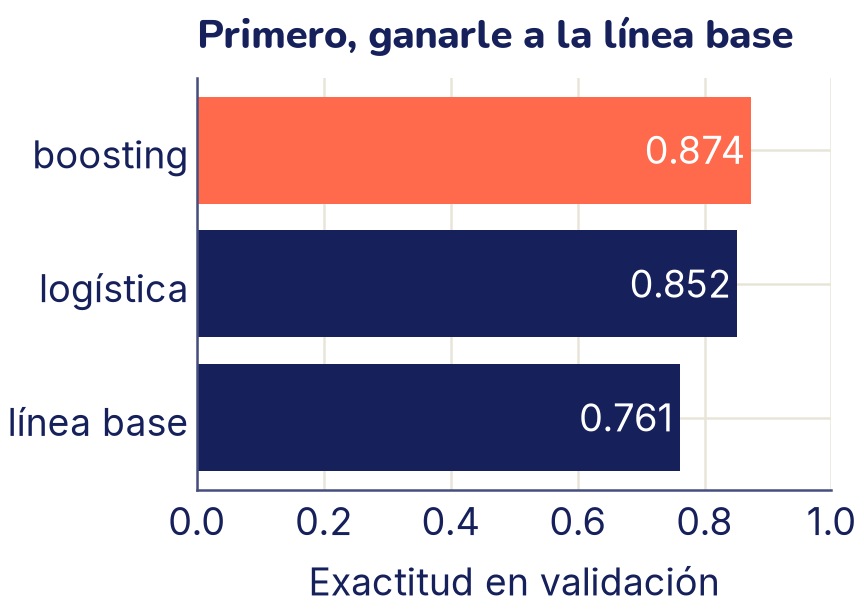

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def crear_pipeline(modelo, numericas=NUMERICAS, categoricas=CATEGORICAS):
    """Prepara las columnas de la tabla y termina en el modelo dado."""
    prep_categoricas = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore",
                                 sparse_output=False))])
    preparar = ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", prep_categoricas, categoricas)])
    return Pipeline([("preparar", preparar), ("modelo", modelo)])

candidatos = {
    "línea base": DummyClassifier(strategy="most_frequent"),
    "logística": LogisticRegression(max_iter=1000),
    "boosting": HistGradientBoostingClassifier(random_state=0),
}
exactitudes = {}
for nombre, estimador in candidatos.items():
    pipe = crear_pipeline(estimador).fit(X_ent, y_ent)
    prob = pipe.predict_proba(X_val)[:, 1]
    exactitudes[nombre] = accuracy_score(y_val, prob >= 0.5)
    print(f"{nombre:10s}  exactitud = {exactitudes[nombre]:.3f}"
          f"   AUC = {roc_auc_score(y_val, prob):.3f}")
modelo = pipe  # el último: el boosting

nombres = list(exactitudes)
colores = ["C1" if n == "boosting" else "C0" for n in nombres]
plt.barh(nombres, list(exactitudes.values()), color=colores)
for i, v in enumerate(exactitudes.values()):
    plt.text(v - 0.01, i, f"{v:.3f}", ha="right", va="center",
             color="white")
plt.xlim(0, 1)
plt.xlabel("Exactitud en validación")
plt.title("Primero, ganarle a la línea base")
plt.show()

La línea base ya acierta el 76,1 %, porque tres de cada cuatro personas ganan menos de 50 000. Por eso una exactitud de 0,874 es menos impresionante de lo que suena: el boosting corrige casi la mitad de los errores de la línea base. Su AUC, 0,927, dice que ordena bien a las personas por probabilidad. Nos quedamos con el boosting. El conjunto de prueba todavía no se tocó.

## Auditar por subgrupos

Ahora sí, la evaluación final en prueba. Además de la exactitud global, calculamos las métricas **dentro de cada grupo** con `groupby`. La función `metricas` recibe la parte de la tabla de un grupo y devuelve:

- `tasa_base`: qué fracción del grupo es realmente positiva (gana más de 50 000);
- `aprobacion`: qué fracción del grupo aprueba el modelo;
- `tvp`: de los positivos del grupo, qué fracción aprueba (la exhaustividad del tema 9);
- `tfp`: de los negativos del grupo, qué fracción aprueba por error;
- `precision` y `exactitud`, como en el tema 9.

In [ ]:
prob_pru = modelo.predict_proba(X_pru)[:, 1]
pred_pru = (prob_pru >= 0.5).astype(int)
print(f"Exactitud en prueba: {accuracy_score(y_pru, pred_pru):.3f}")

def metricas(tabla):
    """Métricas de un grupo. tabla tiene las columnas y y pred."""
    real, pred = tabla["y"], tabla["pred"]
    return pd.Series({
        "n": len(tabla),
        "tasa_base": real.mean(),
        "aprobacion": pred.mean(),
        "tvp": pred[real == 1].mean(),
        "tfp": pred[real == 0].mean(),
        "precision": real[pred == 1].mean(),
        "exactitud": (real == pred).mean(),
    })

auditoria = pd.DataFrame({"y": y_pru.to_numpy(), "pred": pred_pru,
                          "sexo": s_pru.to_numpy()})
por_sexo = auditoria.groupby("sexo")[["y", "pred"]].apply(metricas)
por_sexo["n"] = por_sexo["n"].astype(int)
print(por_sexo.round(3).to_string())

Exactitud en prueba: 0.875
           n  tasa_base  aprobacion    tvp    tfp  precision  exactitud
sexo                                                                   
hombre  6530      0.304       0.255  0.664  0.077      0.789      0.844
mujer   3239      0.109       0.087  0.605  0.023      0.762      0.936


Lee la tabla con calma, porque cada columna cuenta algo distinto:

- **La exactitud es mayor para las mujeres** (0,936 contra 0,844). Parece una buena noticia, pero es la trampa del tema 9: como solo el 10,9 % de las mujeres del conjunto son positivas, decirles «no» a casi todas ya da muchos aciertos.
- **La aprobación** es 25,5 % para los hombres y 8,7 % para las mujeres. Parte de esa diferencia viene de las tasas base distintas, y parte del modelo.
- **La TVP** es la que mide las oportunidades: de las mujeres que sí ganaban más de 50 000, el modelo reconoce al 60,5 %; de los hombres, al 66,4 %. A una mujer que cumple le cuesta más ser aprobada.
- **La TFP** va al revés: el modelo aprueba por error al 7,7 % de los hombres que no cumplen y solo al 2,3 % de las mujeres.

## ¿La diferencia es real? Intervalos de bootstrap

En el conjunto de prueba hay unas 350 mujeres positivas. Con tan pocas, la TVP de 0,605 podría variar bastante con otra muestra. Para saber cuánto, usamos el **bootstrap** que viste en el bagging del tema 11: sacamos muchas muestras **con reemplazo** del mismo tamaño que el grupo, calculamos la métrica en cada una y miramos entre qué valores cae el 95 % central. Ese rango es un **intervalo del 95 %**.

hombre  aprobacion: 0.245–0.266   tvp: 0.643–0.684   exactitud: 0.835–0.853
mujer   aprobacion: 0.077–0.097   tvp: 0.552–0.654   exactitud: 0.928–0.945


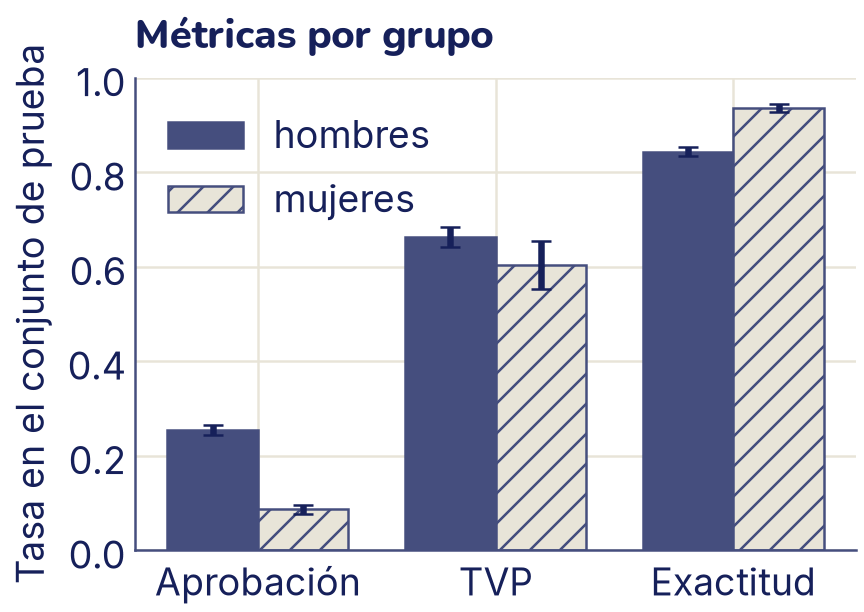

In [ ]:
rng = np.random.default_rng(0)

def intervalos(tabla, repeticiones=1000):
    """Intervalo del 95 % de cada métrica, por bootstrap."""
    muestras = []
    for _ in range(repeticiones):
        filas = rng.integers(0, len(tabla), size=len(tabla))
        muestras.append(metricas(tabla.iloc[filas]))
    muestras = pd.DataFrame(muestras)
    return muestras.quantile([0.025, 0.975])

MOSTRAR = ["aprobacion", "tvp", "exactitud"]
grupos = {g: t for g, t in auditoria.groupby("sexo")}
for g, tabla in grupos.items():
    iv = intervalos(tabla)
    texto = "   ".join(f"{m}: {iv.loc[0.025, m]:.3f}–"
                       f"{iv.loc[0.975, m]:.3f}" for m in MOSTRAR)
    print(f"{g:7s} {texto}")
    grupos[g] = iv

ancho = 0.38
posiciones = np.arange(len(MOSTRAR))
estilos = [("hombre", "hombres", "C2", ""),
           ("mujer", "mujeres", "C3", "//")]
for k, (g, rotulo, color, rayas) in enumerate(estilos):
    valores = por_sexo.loc[g, MOSTRAR].to_numpy(dtype=float)
    iv = grupos[g][MOSTRAR].to_numpy()
    errores = [valores - iv[0], iv[1] - valores]
    plt.bar(posiciones + (k - 0.5) * ancho, valores, ancho, yerr=errores,
            capsize=4, color=color, edgecolor="C2", hatch=rayas,
            ecolor="C0", label=rotulo)
plt.xticks(posiciones, ["Aprobación", "TVP", "Exactitud"])
plt.ylim(0, 1)
plt.ylabel("Tasa en el conjunto de prueba")
plt.title("Métricas por grupo")
plt.legend(loc="upper left")
plt.show()

Los intervalos de la aprobación están muy lejos uno del otro: esa diferencia es clarísima. Los de la TVP se tocan (0,643 a 0,684 para los hombres y 0,552 a 0,654 para las mujeres), y el de las mujeres es más del doble de ancho porque hay menos datos. La diferencia de oportunidades es probable, pero con estos datos no es tan segura como la de aprobación. **Un número sin intervalo no alcanza para afirmar que un grupo es tratado peor**, y un grupo pequeño necesita todavía más cuidado (lo vas a ver en el ejercicio 2).

## Mirar los errores

Las métricas resumen; los ejemplos muestran. Una auditoría siempre incluye una **tabla de errores representativos**: casos tomados al azar, no los más raros, de cada tipo de error y de cada grupo.

In [ ]:
prueba = X_pru.assign(sexo=s_pru, real=y_pru, prob=prob_pru.round(2))
errores_fn = prueba[(prueba["real"] == 1) & (prueba["prob"] < 0.5)]
errores_fp = prueba[(prueba["real"] == 0) & (prueba["prob"] >= 0.5)]
print("Falsos negativos por grupo:",
      errores_fn["sexo"].value_counts().to_dict())
print("Falsos positivos por grupo:",
      errores_fp["sexo"].value_counts().to_dict())

columnas = ["sexo", "edad", "anios_estudio", "estado_civil", "horas",
            "prob"]
# Tres falsos negativos al azar de cada grupo
muestra = errores_fn.groupby("sexo").sample(3, random_state=0)
print(muestra[columnas].to_string())

Falsos negativos por grupo: {'hombre': 661, 'mujer': 138}
Falsos positivos por grupo: {'hombre': 358, 'mujer': 67}
         sexo  edad  anios_estudio        estado_civil  horas  prob
3340   hombre    43             10  Married-civ-spouse     44  0.45
26625  hombre    33              3  Married-civ-spouse     50  0.13
44362  hombre    31              9  Married-civ-spouse     50  0.25
2742    mujer    39             14            Divorced     30  0.03
833     mujer    36             14            Divorced     40  0.13
3178    mujer    45              9  Married-civ-spouse     40  0.18


Los hombres acumulan más errores de los dos tipos porque son el doble y su tasa base es más alta. En la muestra, los falsos negativos de los hombres están casados, y dos de las tres mujeres están divorciadas, tienen 14 años de estudio y el modelo les da probabilidades bajísimas (0,03 y 0,13). Tres casos no prueban nada, pero dan una pista para investigar: **¿cuánto pesa el estado civil en las decisiones del modelo?**

## ¿En qué se apoya el modelo?

La importancia por permutación del tema 11 responde esa pregunta: desordena una columna del conjunto de prueba y mide cuánta exactitud se pierde.

estado_civil      +0.055
ganancia_capital  +0.048
anios_estudio     +0.034
edad              +0.020
ocupacion         +0.016


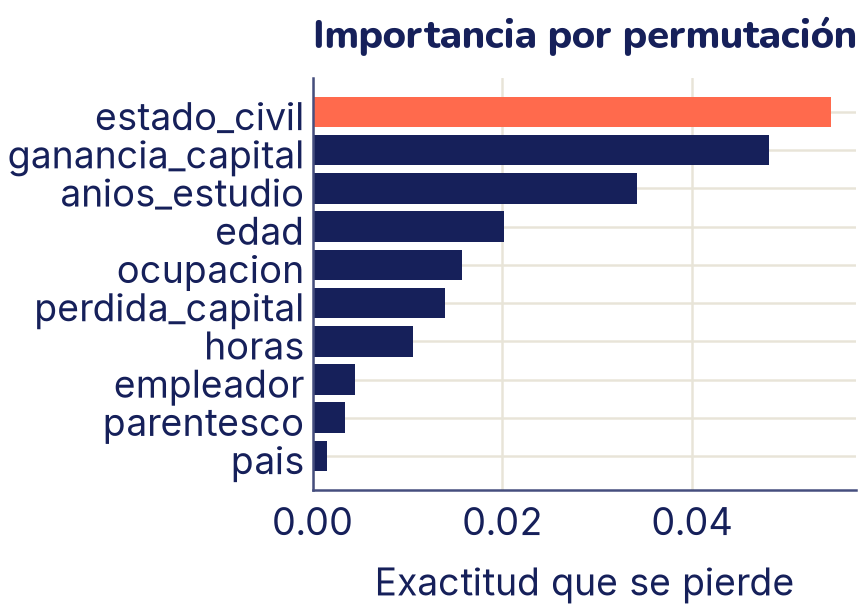

In [ ]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(modelo, X_pru, y_pru, n_repeats=5,
                             random_state=0)
orden = np.argsort(imp.importances_mean)
for j in orden[::-1][:5]:
    print(f"{X.columns[j]:17s} {imp.importances_mean[j]:+.3f}")

colores = ["C1" if j == orden[-1] else "C0" for j in orden]
plt.barh(X.columns[orden], imp.importances_mean[orden], color=colores)
plt.xlabel("Exactitud que se pierde")
plt.title("Importancia por permutación")
plt.show()

La variable de la que más depende el modelo es `estado_civil`, más que los años de estudio o las horas trabajadas. En estos datos, estar casado se asocia con ingresos altos, y el estado civil, junto con el parentesco, guarda mucha información sobre el sexo y la situación familiar. `parentesco` aparece casi en cero, pero no porque no sirva: como dice casi lo mismo que `estado_civil`, desordenar solo una de las dos le quita poco al modelo (la misma advertencia del tema 11 sobre variables muy relacionadas). La explicación no acusa ni absuelve al modelo: te dice **dónde mirar**.

## Métricas de equidad

Hay muchas definiciones de «justo». Las dos más usadas comparan las tasas que ya calculaste. Llamemos *ŷ* a la decisión del modelo (1 = aprobar), *y* a la respuesta real y *G* al grupo.

**Paridad demográfica**: todos los grupos se aprueban en la misma proporción, sin importar cuántos cumplen.

$$P ( \hat{y} = 1 \mid G = \text{A} ) = P ( \hat{y} = 1 \mid G = \text{B} )$$

**Igualdad de oportunidades** ([Hardt, Price y Srebro, 2016](https://arxiv.org/abs/1610.02413)): entre quienes **sí cumplen**, todos los grupos se aprueban en la misma proporción. Es decir, la TVP es igual.

$$P ( \hat{y} = 1 \mid y = 1 , G = \text{A} ) = P ( \hat{y} = 1 \mid y = 1 , G = \text{B} )$$

Si además se pide que la TFP sea igual, se llama **igualdad de probabilidades** (*equalized odds*). Y otra familia pide que la **precisión** sea igual: que una aprobación «valga lo mismo» en cada grupo.

¿Por qué no pedir todas? La paridad y la igualdad de oportunidades, solas, se pueden cumplir juntas, pero pagando con más errores (lo vas a ver en el ejercicio 1). Lo que **es matemáticamente imposible**, cuando las tasas base de los grupos son distintas y el modelo no es perfecto, es cumplir la paridad junto con la igualdad de probabilidades (misma TVP **y** misma TFP), o la igualdad de probabilidades junto con la misma precisión ([Kleinberg, Mullainathan y Raghavan, 2016](https://arxiv.org/abs/1609.05807); Chouldechova, 2017). Es el choque que viste en la actividad. La forma más directa de moverse entre ellas es usar **un umbral distinto para cada grupo**. Los elegimos en validación y medimos una sola vez en prueba. Para simplificar, el umbral de los hombres queda en 0,5 y buscamos el de las mujeres.

In [ ]:
prob_val = modelo.predict_proba(X_val)[:, 1]
UMBRALES = np.round(np.arange(0.05, 0.96, 0.01), 2)

def tasas(real, prob, umbral):
    """Tasas de aprobación, de verdaderos positivos (TVP) y de falsos
    positivos (TFP)."""
    pred = prob >= umbral
    return pred.mean(), pred[real == 1].mean(), pred[real == 0].mean()

def umbral_parecido(real, prob, objetivo, cual):
    """El umbral cuya tasa (0: aprobación, 1: TVP) queda más cerca
    del objetivo."""
    distancias = [abs(tasas(real, prob, u)[cual] - objetivo)
                  for u in UMBRALES]
    return UMBRALES[int(np.argmin(distancias))]

# En validación: los hombres quedan con 0,5 y se busca el de las mujeres
h, m = (s_val == "hombre").to_numpy(), (s_val == "mujer").to_numpy()
yv = y_val.to_numpy()
meta = tasas(yv[h], prob_val[h], 0.5)
politicas = {
    "un solo umbral": 0.5,
    "igualar aprobación": umbral_parecido(yv[m], prob_val[m], meta[0], 0),
    "igualar oportunidades": umbral_parecido(yv[m], prob_val[m],
                                             meta[1], 1),
}

# En prueba: cada política se mide una sola vez
hp, mp = (s_pru == "hombre").to_numpy(), (s_pru == "mujer").to_numpy()
yp = y_pru.to_numpy()
print("política               umbral M  aprob H/M  TVP H/M    TFP H/M"
      "    exactitud")
for nombre, u_m in politicas.items():
    umbral = np.where(mp, u_m, 0.5)
    pred = prob_pru >= umbral
    ah, th, fh = tasas(yp[hp], prob_pru[hp], 0.5)
    am, tm, fm = tasas(yp[mp], prob_pru[mp], u_m)
    print(f"{nombre:22s} {u_m:.2f}      {ah:.2f}/{am:.2f}  "
          f"{th:.2f}/{tm:.2f}  {fh:.2f}/{fm:.2f}  "
          f"{(pred == yp).mean():.3f}")

política               umbral M  aprob H/M  TVP H/M    TFP H/M    exactitud
un solo umbral         0.50      0.26/0.09  0.66/0.60  0.08/0.02  0.875
igualar aprobación     0.08      0.26/0.25  0.66/0.88  0.08/0.18  0.840
igualar oportunidades  0.45      0.26/0.10  0.66/0.65  0.08/0.03  0.874


- **Igualar la aprobación** exige bajar el umbral de las mujeres hasta 0,08. Las tasas de aprobación quedan casi iguales (0,26 y 0,25), pero se aprueba a muchas mujeres que no cumplen: su TFP sube de 0,02 a 0,18, más del doble de la de los hombres (0,08). De paso se aprueba a casi todas las que sí cumplen: su TVP sube a 0,88, muy por encima de la de los hombres. La exactitud global cae de 0,875 a 0,840.
- **Igualar las oportunidades** solo pide bajar el umbral de las mujeres a 0,45. La TVP queda en 0,66 y 0,65, y la exactitud casi no cambia (0,874). La aprobación sigue siendo distinta, porque las tasas base lo son.

¿Y si movemos los dos umbrales a la vez? Probamos todas las parejas de umbrales entre 0,05 y 0,95 en validación y, para cada diferencia permitida entre grupos, buscamos la mejor exactitud posible. Esa curva es la **frontera del compromiso** entre exactitud y equidad.

Diferencia de aprobación <= 0.10: mejor exactitud 0.868
Diferencia de aprobación <= 0.05: mejor exactitud 0.861
Diferencia de aprobación <= 0.02: mejor exactitud 0.855
Diferencia de TVP <= 0.10: mejor exactitud 0.875
Diferencia de TVP <= 0.05: mejor exactitud 0.875
Diferencia de TVP <= 0.02: mejor exactitud 0.874


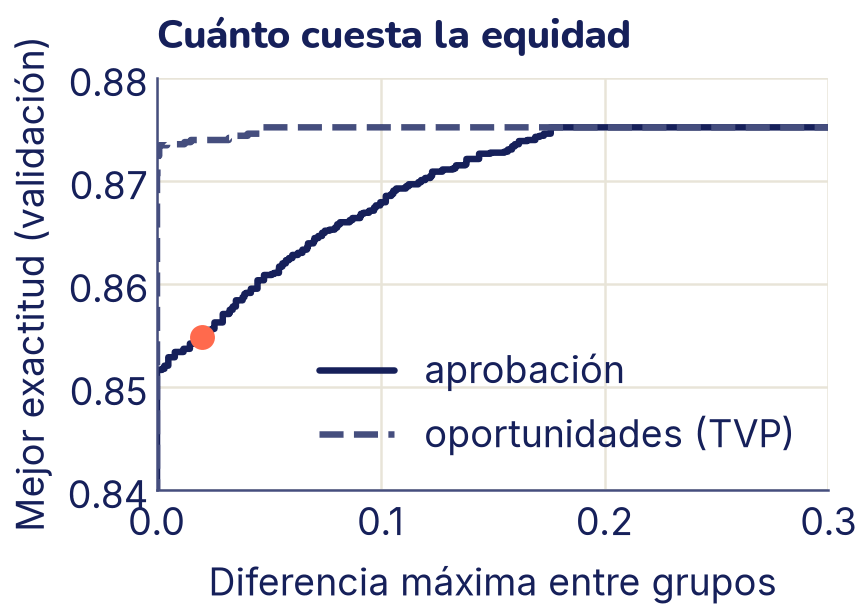

In [ ]:
# Todas las parejas de umbrales (hombres, mujeres), en validación
rejilla = np.round(np.arange(0.05, 0.96, 0.01), 2)
puntos = []
for u_h in rejilla:
    for u_m in rejilla:
        pred = prob_val >= np.where(m, u_m, u_h)
        dif_aprob = abs(pred[h].mean() - pred[m].mean())
        dif_tvp = abs(pred[h & (yv == 1)].mean()
                      - pred[m & (yv == 1)].mean())
        puntos.append((dif_aprob, dif_tvp, (pred == yv).mean()))
puntos = np.array(puntos)

def frontera(diferencias, exactitud):
    """Para cada diferencia, la mejor exactitud que no la supera."""
    orden = np.argsort(diferencias)
    return diferencias[orden], np.maximum.accumulate(exactitud[orden])

for col, nombre in [(0, "aprobación"), (1, "TVP")]:
    for tope in [0.10, 0.05, 0.02]:
        ok = puntos[:, col] <= tope
        print(f"Diferencia de {nombre} <= {tope:.2f}: mejor exactitud "
              f"{puntos[ok, 2].max():.3f}")

x_a, y_a = frontera(puntos[:, 0], puntos[:, 2])
x_t, y_t = frontera(puntos[:, 1], puntos[:, 2])
plt.step(x_a, y_a, where="post", color="C0", label="aprobación")
plt.step(x_t, y_t, where="post", color="C2", linestyle="--",
         label="oportunidades (TVP)")
ok = puntos[:, 0] <= 0.02
plt.scatter([0.02], [puntos[ok, 2].max()], s=80, color="C1", zorder=3)
plt.xlim(0, 0.3)
plt.ylim(0.84, 0.88)
plt.xlabel("Diferencia máxima entre grupos")
plt.ylabel("Mejor exactitud (validación)")
plt.title("Cuánto cuesta la equidad")
plt.legend(loc="lower right")
plt.show()

En este problema, igualar las oportunidades es casi gratis: exigir que la TVP de los dos grupos no difiera en más de 0,02 deja la exactitud en 0,874. Igualar la aprobación cuesta más: con una diferencia de 0,02 como máximo, la mejor exactitud baja a 0,855 (el punto resaltado), unos dos puntos menos. Esto **no es una ley general**: en otros datos el compromiso puede ser mucho más caro. Por eso se mide.

¿Cuál elegir? Depende de la pregunta, y la respuesta va escrita en la ficha:

- Si las etiquetas son confiables y la decisión debe premiar a quien cumple (por ejemplo, devolver un préstamo), la **igualdad de oportunidades** suele ser la más defendible.
- Si sospechas que **las propias etiquetas están sesgadas** (el «ingreso alto» de 1994 ya trae la brecha salarial adentro), igualar las oportunidades medidas con esas etiquetas también hereda el sesgo. Entonces se discute la paridad, o mejor, cambiar los datos o la pregunta.
- Usar el sexo o el origen de una persona para darle un umbral distinto **es tratarla distinto por su grupo**. En muchos países eso está regulado o prohibido en decisiones como el crédito o el empleo. Antes de aplicarlo hay que consultar la ley y a las personas afectadas. A veces la mejor salida no es un truco de umbrales, sino mejores datos, otras variables o no automatizar esa decisión.

## La ficha del modelo

Una **ficha de modelo** (*model card*, [Mitchell y otros, 2019](https://arxiv.org/abs/1810.03993)) es un documento corto que acompaña a un modelo y le dice a quien lo use qué hace, cómo se midió y dónde falla. Su pariente es la **ficha de datos** (*datasheet*, [Gebru y otros, 2018](https://arxiv.org/abs/1803.09010)), que cuenta de dónde vienen los datos, quién los recogió y con qué permisos. Esta es la ficha del modelo de este tema, con los números de arriba:

**Ficha del modelo: ¿ingreso mayor a 50 000 dólares? (ejercicio de auditoría)**

- **Qué es.** Un `HistGradientBoostingClassifier` de scikit-learn con los hiperparámetros por defecto, dentro de un `Pipeline` (estandarizar las numéricas e imputar y pasar a one-hot las categóricas). Entrenado en 29 305 personas.
- **Uso previsto.** Material de estudio para aprender a auditar un clasificador.
- **Usos fuera de alcance.** Cualquier decisión real sobre personas: crédito, empleo, vivienda o beneficios. Los datos son de otro país y de 1994.
- **Datos.** Adult (UCI, CC BY 4.0), 48 842 personas del censo de los Estados Unidos de 1994. División estratificada por ingreso y sexo: 60 % entrenamiento, 20 % validación y 20 % prueba. Variables usadas: edad, empleador, años de estudio, estado civil, ocupación, parentesco, ganancia y pérdida de capital, horas por semana y país. No usa sexo ni raza, pero `parentesco` y `estado_civil` funcionan como proxies del sexo.
- **Métricas globales (prueba).** Exactitud 0,875 frente a 0,761 de la línea base. AUC 0,927 en validación.
- **Métricas por grupo (prueba, umbral 0,5).** Aprobación: hombres 0,255, mujeres 0,087. TVP: hombres 0,664 (intervalo del 95 %: 0,643 a 0,684), mujeres 0,605 (0,552 a 0,654). TFP: 0,077 y 0,023.
- **Consideraciones éticas.** Las etiquetas reflejan la desigualdad salarial de 1994. Igualar las oportunidades con umbrales por grupo costaría poco en exactitud (0,875 a 0,874), pero implica usar el sexo en la decisión.
- **Limitaciones.** No se auditaron grupos pequeños con suficiente cuidado (ver el ejercicio 2), ni combinaciones de atributos (por ejemplo, mujeres de un origen determinado). La variable más influyente es el estado civil.
- **Quién lo hizo y cuándo.** Escribe aquí tu nombre, la fecha y la versión de las librerías.

## La plantilla del proyecto final

Tu proyecto final (lo describe el mini-proyecto de la ficha de ejercicios) se entrega como un cuaderno de Colab que tú armas con estas secciones, en este orden. Cada sección empieza con una celda de texto que explica lo que hace la siguiente celda de código.

1. **La pregunta.** Una o dos frases: qué predices, para quién, qué decisión se tomaría y qué error cuesta más. Elige la métrica principal aquí, antes de ver resultados.
2. **Los datos.** Origen, licencia y fecha. Cuántos ejemplos y qué columnas. Si hay datos personales, cuáles y por qué los necesitas. Un gráfico de exploración (tema 4). La división en entrenamiento, validación y prueba, con la semilla fija.
3. **La línea base.** El modelo más simple y su puntaje en validación.
4. **El modelo y las iteraciones.** Una tabla-bitácora con cada intento: qué cambiaste, puntaje en validación y tiempo de entrenamiento. Explica por qué elegiste el modelo final.
5. **La evaluación final.** Una sola vez en prueba: la métrica principal, la matriz de confusión o el gráfico de residuos, y la comparación con la línea base.
6. **El análisis por subgrupos y los errores.** Métricas por grupo con intervalos de bootstrap (si tus datos tienen grupos con sentido: región, idioma, tipo de foto, hablante…), una tabla de errores representativos y la importancia de las variables o ejemplos de lo que el modelo mira.
7. **La ficha del modelo.** Con las secciones de la ficha de arriba.
8. **Qué harías con más tiempo.** Tres ideas concretas.

## IA responsable, más allá de las métricas

Medir por grupos es una parte. Un proyecto de IA también toca personas de otras maneras.

### Privacidad y datos personales

Un **dato personal** es cualquier información sobre una persona identificada o que se pueda identificar: el nombre, el carnet, una foto de la cara, la voz, la ubicación del celular, las notas del colegio. Borrar el nombre **no anonimiza**: con unas pocas columnas comunes, como la edad, el sexo y la ocupación, muchas personas quedan únicas en la tabla y se las puede reconocer cruzando con otra fuente (lo vas a medir en el ejercicio 6). Algunas reglas prácticas para tu proyecto:

- **Recoge solo lo que necesitas** (minimización) y para un fin que explicas (finalidad).
- **Pide permiso** para usar fotos, voces o textos de otras personas, y diles para qué.
- **No subas datos personales de otros** a servicios en línea, incluidos los chats con modelos de lenguaje.
- Guarda los datos con cuidado y bórralos cuando el proyecto termine.

### Qué dice la normativa en Bolivia

Esto es lo que se puede verificar a octubre de 2026, con las fuentes:

- La [Constitución Política del Estado](https://tcpbolivia.bo/wp-content/uploads/2025/04/CPE_2009.pdf) (2009) reconoce en el artículo 21 el derecho «a la privacidad, intimidad, honra, honor, propia imagen y dignidad», y en el artículo 25 la inviolabilidad del domicilio y el secreto de las comunicaciones privadas.
- Los artículos 130 y 131 crean la **Acción de Protección de Privacidad**. Puede presentarla quien no pueda conocer, objetar u obtener que se eliminen o corrijan sus datos registrados en archivos o bancos de datos públicos o privados, por cualquier medio, incluido el informático. Si el juez la declara procedente, ordena revelar, eliminar o rectificar esos datos.
- Bolivia **no tiene todavía una ley general de protección de datos personales**. La Agencia de Gobierno Electrónico y Tecnologías de Información y Comunicación (AGETIC) socializó un proyecto de ley en 2025 ([boletín de la AGETIC de septiembre de 2025](https://agetic.gob.bo/sites/default/files/2025-09/Boletin%20Digital%20037%20pdf.pdf)), y en septiembre de 2026 la prensa seguía informando que no se había aprobado ([Opinión, 16 de septiembre de 2026](https://www.opinion.com.bo/tendencias/quien-queda-tus-datos-bolivia-todavia-tiene-ley-que-obligue-responder/20260916111314996213.html)). Si lees esto más adelante, revisa la [Gaceta Oficial de Bolivia](https://www.gacetaoficialdebolivia.gob.bo/): la situación puede haber cambiado.

Dos marcos internacionales sirven de referencia. La [Ley de IA de la Unión Europea](https://eur-lex.europa.eu/legal-content/ES/TXT/?uri=CELEX:32024R1689) (Reglamento 2024/1689) clasifica los sistemas por su nivel de riesgo y considera de **alto riesgo**, entre otros, los que evalúan la solvencia de una persona para darle crédito, como el banco imaginario de este tema. La [Recomendación sobre la ética de la inteligencia artificial de la UNESCO](https://www.unesco.org/es/artificial-intelligence/recommendation-ethics) (2021), adoptada por sus Estados miembros, pide proteger la privacidad, evitar la discriminación, ser transparentes y medir el impacto ambiental.

### Sesgos: de dónde vienen

El sesgo de Adult es **histórico**: los datos registran bien un mundo desigual. Hay otros tipos que vas a encontrar en tu proyecto:

- **De representación**: un grupo casi no aparece. En Adult, la categoría «otra» de origen tiene menos de 100 personas en prueba, y sus métricas casi no se pueden medir. Un modelo de voz entrenado con hablantes de una ciudad entiende peor los acentos de otras regiones.
- **De medición o de etiqueta**: lo que se mide no es exactamente lo que importa. «Ganó más de 50 000» no es «puede pagar un crédito», y «lo arrestaron» no es «cometió un delito».
- **De despliegue**: el modelo se usa en un lugar o una época distintos de los de sus datos, como usar un censo de 1994 para decidir en 2026.

### Transparencia y explicabilidad

Las personas afectadas por una decisión automática tienen razones para preguntar por qué. Las herramientas de este tema (la importancia por permutación, la tabla de errores y la ficha del modelo) son el mínimo. Y una regla simple: **di cuándo algo lo hizo una IA**, sea una decisión, un texto o una imagen.

### IA generativa y desinformación

Los modelos de los temas 24 y 29 escriben textos e imágenes convincentes, y por eso sirven también para fabricar noticias, voces o fotos falsas de personas reales. Al compartir algo, pregúntate de dónde viene; al crear algo con IA, etiquétalo. Y recuerda que un modelo de lenguaje puede inventar datos, citas o referencias con total seguridad: lo que diga se verifica en una fuente.

### Impacto ambiental

Entrenar y usar modelos consume electricidad y agua para enfriar los centros de datos. Según la [Agencia Internacional de Energía](https://www.iea.org/reports/energy-and-ai/executive-summary), los centros de datos usaron alrededor del 1,5 % de la electricidad mundial en 2024 (unos 415 TWh), y prevé que su consumo se duplique con creces hasta unos 945 TWh en 2030. En tu escala, lo responsable es lo mismo que lo eficiente: empezar con modelos pequeños, reutilizar modelos preentrenados en lugar de entrenar desde cero, no repetir entrenamientos largos sin una pregunta clara y anotar en la ficha cuánto tiempo de cómputo usaste.

### Usar modelos de lenguaje en el estudio, con honestidad

Un asistente como los del tema 24 puede ser un buen tutor, si lo usas para **entender**, no para **evitar** entender:

- Pídele que te explique un error o un concepto, y luego escribe tú el código.
- Todo el código que te dé se **ejecuta y se comprueba**; no lo copies sin entender cada línea.
- **Declara** en tu proyecto para qué usaste un asistente («me ayudó a depurar la función de bootstrap»). Ocultarlo es tan deshonesto como copiar de un compañero.
- Tienes que poder explicar con tus palabras cualquier parte de tu proyecto, porque eso es lo que aprendiste.

### Derechos de autor y licencias de datos

Que algo esté en internet no quiere decir que puedas usarlo. Antes de usar datos o un modelo, busca su **licencia**: CC BY (como Adult) permite casi todo citando a los autores; CC BY-NC prohíbe el uso comercial; y un dataset sin licencia no es libre, simplemente no sabes qué permite. Los modelos preentrenados de los temas 21 a 26 también tienen licencias, que conviene leer. Las fotos y grabaciones de personas necesitan, además, su permiso.

## Lo que aprendiste

- Un proyecto de IA sigue un ciclo: **pregunta, datos, línea base, iteración y evaluación final**, con la prueba guardada hasta el final.
- La exactitud global puede esconder que un modelo trata peor a un grupo. Se **audita por subgrupos** con `groupby`, mirando la aprobación, la TVP y la TFP, con **intervalos de bootstrap**.
- Borrar un atributo sensible no basta: otras variables lo **delatan**.
- La **paridad demográfica** y la **igualdad de oportunidades** piden cosas distintas, y con tasas base distintas no se pueden cumplir todas. Mover umbrales por grupo muestra el **compromiso**, y la elección se justifica por escrito.
- Una **ficha de modelo** dice qué hace el modelo, cómo se midió, para qué no sirve y dónde falla.
- La privacidad, los sesgos, la transparencia, la desinformación, el consumo de energía, las licencias y el uso honesto de los asistentes son parte del trabajo, no un agregado.

## El final de la ruta, y lo que sigue

Empezaste esta ruta escribiendo `print` en el tema 1. Desde entonces programaste el descenso de gradiente a mano, entrenaste árboles, redes convolucionales y transformers, reutilizaste modelos que vieron millones de ejemplos y, en este tema, aprendiste a preguntarle a un modelo a quién le falla. Lo que sigue depende de lo que más te haya gustado:

- **La matemática de fondo.** Álgebra lineal, cálculo de varias variables y probabilidad. El libro [*Mathematics for Machine Learning*](https://mml-book.github.io/) se puede leer gratis en línea.
- **Redes neuronales en profundidad.** [*Dive into Deep Learning*](https://d2l.ai/) (gratuito, con código en PyTorch) y los [tutoriales oficiales de PyTorch](https://pytorch.org/tutorials/) retoman los temas 16 a 29 con más detalle.
- **Modelos preentrenados y lenguaje.** Los [cursos de Hugging Face](https://huggingface.co/learn) siguen donde terminaron los temas 21 a 25.
- **Lo que la ruta no cubrió.** El aprendizaje por refuerzo y por imitación (agentes que aprenden probando o copiando a un experto) quedó en el tema optativo 20 bis; si no lo hiciste, es un buen siguiente paso. Tampoco cubrió las redes de grafos, la inferencia causal (distinguir correlación de causa) y cómo poner un modelo en producción y mantenerlo.
- **Problemas de tu entorno.** Busca datos abiertos sobre algo que conozcas: el clima de tu ciudad, el idioma que hablas en casa, los cultivos de tu región. Un proyecto pequeño sobre un problema real enseña más que un tutorial.
- **Leer y replicar.** Elige un artículo corto de [arXiv](https://arxiv.org/) sobre un tema de la ruta y trata de reproducir uno de sus resultados con su código.

Sigue haciendo lo que hiciste en cada tema: primero la intuición, después el código, y siempre medir con honestidad.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `datos`, `X`, `X_ent`, `y_ent`, `X_pru`, `y_pru`, `s_ent`, `s_pru`, `crear_pipeline`, `metricas`, `intervalos`, `auditoria`, `por_sexo`, `HistGradientBoostingClassifier` y `roc_auc_score`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. Métricas de equidad a mano

Un modelo decide sobre 100 personas del grupo A y 100 del grupo B. En el grupo A, 40 personas son positivas: el modelo aprueba a 30 de ellas y a 10 de las 60 negativas. En el grupo B, 20 personas son positivas: el modelo aprueba a 10 de ellas y a 5 de las 80 negativas.

a) Calcula para cada grupo la tasa de aprobación, la TVP, la TFP y la precisión. Compruébalo con la función `metricas`.

b) ¿Cumple el modelo la paridad demográfica? ¿Y la igualdad de oportunidades?

c) Si en el grupo B se aprobara a 15 de los 20 positivos (y a los mismos 5 negativos), ¿qué criterio se cumpliría? ¿Se cumplirían los dos?

<details>
<summary>Respuesta</summary>

a) Grupo A: aprobación (30 + 10) / 100 = **0,40**; TVP 30 / 40 = **0,75**; TFP 10 / 60 ≈ **0,167**; precisión 30 / 40 = **0,75**. Grupo B: aprobación 15 / 100 = **0,15**; TVP 10 / 20 = **0,50**; TFP 5 / 80 ≈ **0,062**; precisión 10 / 15 ≈ **0,667**.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
tabla = pd.DataFrame({
    "grupo": ["A"] * 100 + ["B"] * 100,
    "y":    [1] * 40 + [0] * 60 + [1] * 20 + [0] * 80,
    "pred": [1] * 30 + [0] * 10 + [1] * 10 + [0] * 50
          + [1] * 10 + [0] * 10 + [1] * 5 + [0] * 75,
})
resumen = tabla.groupby("grupo")[["y", "pred"]].apply(metricas)
print(resumen[["aprobacion", "tvp", "tfp", "precision"]].round(3))

<details>
<summary>Respuesta (sigue)</summary>

b) Ninguno de los dos: la aprobación es 0,40 contra 0,15 y la TVP, 0,75 contra 0,50.

c) La TVP de B sería 15 / 20 = 0,75, igual a la de A: se cumpliría la **igualdad de oportunidades**. La aprobación de B sería (15 + 5) / 100 = 0,20, todavía lejos de 0,40: la paridad **no** se cumpliría. ¿Se pueden cumplir los dos? Sí: aprobando a 25 negativos de B (en vez de 5), la aprobación de B sube a (15 + 25) / 100 = 0,40 y la TVP sigue en 0,75. Pero la TFP de B pasaría de 5 / 80 ≈ 0,06 a 25 / 80 ≈ 0,31, casi el doble de la de A (0,167), y B tendría 20 errores más: se cumplen los dos criterios a costa de muchos más errores. Si además pides la misma TFP (igualdad de probabilidades), ya no se puede: con TVP 0,75 y TFP 0,167, B aprobaría a 0,75 · 20 + 0,167 · 80 ≈ 28 personas, no a 40. Es el mismo choque que viste en la actividad.

</details>

### 2. Auditar por origen

La columna `raza` de Adult (el «origen», como lo llamamos en este tema) tiene las cinco categorías que usaba el censo de los Estados Unidos en 1994. Esas categorías no corresponden a cómo se pregunta la identidad en Bolivia: en el Censo 2024, la pregunta es de autoidentificación con una nación o pueblo indígena originario campesino o afroboliviano. Audita el modelo de la teoría por esa columna: tamaño de cada grupo, tasa base, aprobación y TVP, con el intervalo de bootstrap de la TVP. ¿En qué grupos puedes afirmar algo y en cuáles no?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
# Las categorías del censo de 1994, traducidas
nombres = {"White": "blanca", "Black": "negra",
           "Asian-Pac-Islander": "asiática o del Pacífico",
           "Amer-Indian-Eskimo": "indígena americana", "Other": "otra"}
raza = datos.loc[X_pru.index, "raza"].astype(str).map(nombres)
auditoria["raza"] = raza.to_numpy()
por_raza = auditoria.groupby("raza")[["y", "pred"]].apply(metricas)
por_raza["n"] = por_raza["n"].astype(int)
print(por_raza[["n", "tasa_base", "aprobacion", "tvp"]].round(3))

print("Intervalo del 95 % de la TVP:")
for r, t in auditoria.groupby("raza"):
    iv = intervalos(t[["y", "pred"]], repeticiones=500)
    print(f"  {r:23s} {iv.loc[0.025, 'tvp']:.2f}–"
          f"{iv.loc[0.975, 'tvp']:.2f}")

<details>
<summary>Respuesta</summary>

- Los grupos son muy desiguales en tamaño: 8329 personas en «blanca» y menos de 100 en «indígena americana» y en «otra».
- En «negra», la TVP es 0,518, con un intervalo de 0,42 a 0,62 que **no** se toca con el de «blanca» (0,64 a 0,68): de las personas de ese grupo que sí ganaban más de 50 000, el modelo reconoce bastante menos. Es una diferencia que vale la pena reportar y estudiar.
- En «indígena americana» y en «otra», los intervalos van de 0,50 a 1,00 y de 0,03 a 0,67: con tan pocas personas positivas (unas 10 en cada grupo), **no se puede afirmar nada**. Que la TVP de «indígena americana» sea 0,778 no quiere decir que el modelo las trate mejor.
- La lección para tu proyecto: reporta siempre el tamaño de cada grupo junto a sus métricas, y si un grupo es demasiado pequeño, dilo como una **limitación** en la ficha, en lugar de sacar conclusiones. La solución de fondo es conseguir más datos de ese grupo.

</details>

### 3. Las columnas delatan el sexo

El modelo de la teoría no usa la columna `sexo`. Entrena un clasificador que intente **adivinar el sexo** con las mismas diez columnas que usa el modelo, y mide su AUC en prueba. ¿Qué dice el resultado sobre la idea de «quitar la columna y listo»?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
# El objetivo ahora es el sexo, con las mismas columnas de antes
es_mujer = (s_ent == "mujer").astype(int)
detector = crear_pipeline(HistGradientBoostingClassifier(random_state=0))
detector.fit(X_ent, es_mujer)
prob_mujer = detector.predict_proba(X_pru)[:, 1]
print(f"AUC para adivinar el sexo: "
      f"{roc_auc_score(s_pru == 'mujer', prob_mujer):.3f}")

<details>
<summary>Respuesta</summary>

Un AUC de 0,932 quiere decir que, con las columnas que «no son el sexo», un modelo ordena casi perfectamente a las personas según su sexo. La información sigue ahí, sobre todo en `parentesco` y `estado_civil`. Quitar el atributo sensible (la llamada **equidad por desconocimiento**) no garantiza que el modelo no lo use indirectamente. Además, sin la columna ya no se puede auditar: por eso en la teoría la guardamos aparte.

</details>

### 4. ¿Y si quitamos el estado civil y el parentesco?

Entrena el mismo boosting sin `estado_civil` ni `parentesco`, las dos columnas que delatan el sexo. Compara la exactitud y las tasas de aprobación y TVP por grupo con las del modelo original. ¿Se volvió más justo? ¿A qué costo?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
# Las mismas columnas, menos estado_civil y parentesco
otras = ["empleador", "ocupacion", "pais"]
sin_familia = crear_pipeline(
    HistGradientBoostingClassifier(random_state=0), categoricas=otras)
sin_familia.fit(X_ent, y_ent)
pred_sin = sin_familia.predict(X_pru)

tabla_sin = pd.DataFrame({"y": y_pru.to_numpy(), "pred": pred_sin,
                          "sexo": s_pru.to_numpy()})
sin = tabla_sin.groupby("sexo")[["y", "pred"]].apply(metricas)
print(f"Exactitud sin esas columnas: {(pred_sin == y_pru).mean():.3f}")
comparar = pd.DataFrame({
    "aprob_con": por_sexo["aprobacion"], "aprob_sin": sin["aprobacion"],
    "tvp_con": por_sexo["tvp"], "tvp_sin": sin["tvp"]})
print(comparar.round(3))

<details>
<summary>Respuesta</summary>

- La diferencia de aprobación entre hombres y mujeres baja de 0,168 (0,255 − 0,087) a 0,100 (0,178 − 0,078), y la de TVP, de 0,059 a 0,048.
- Pero la exactitud cae de 0,875 a 0,848, y la TVP baja **para los dos grupos**: el modelo reconoce a muchas menos personas que sí cumplen, mujeres incluidas (de 0,605 a 0,446).
- Las brechas se achicaron más porque el modelo empeoró para todos que porque tratara mejor a las mujeres. Este es un caso típico: una intervención que mejora una métrica de equidad puede empeorar lo que le pasa a cada persona. Por eso se reportan las tasas de cada grupo, no solo la diferencia entre ellas.

</details>

### 5. ¿Qué criterio de equidad?

Para cada situación, di si te parece más defendible pedir **paridad demográfica**, **igualdad de oportunidades** o **ninguna** de las dos (y por qué). No hay una única respuesta correcta, pero sí respuestas mejor y peor justificadas.

1. Un modelo que elige a quién ofrecerle una beca de estudio: predice si un estudiante tendrá buen rendimiento en la universidad, y se entrenó con los promedios de colegio de exalumnos que vienen de colegios con recursos muy distintos (fiscales, de convenio y particulares).
2. Un detector de una enfermedad que afecta mucho más a las personas mayores que a las jóvenes.
3. Un filtro que decide qué currículums lee una persona de recursos humanos, entrenado con quién fue contratado en los últimos diez años en una empresa con casi solo hombres en los puestos técnicos.
4. Un modelo que recomienda canciones.

<details>
<summary>Respuesta</summary>

1. Las notas miden el mérito, pero también los recursos del colegio: la etiqueta trae sesgo. Hay buenos argumentos para alguna forma de paridad entre colegios, o mejor, para medir el mérito dentro de cada contexto. Igualar las oportunidades medidas con esas mismas notas heredaría la desigualdad.
2. **Igualdad de oportunidades** (o igualdad de probabilidades): lo que importa es detectar igual de bien a los enfermos de cada edad. La paridad sería absurda, porque la enfermedad de verdad es más frecuente en un grupo.
3. Las etiquetas («fue contratado») registran una historia de exclusión, así que la igualdad de oportunidades medida con ellas no basta. Aquí se justifica mirar la **paridad** al menos en la etapa de preselección, y sobre todo revisar si hay que automatizar esa decisión.
4. Probablemente **ninguna** de las dos en el sentido de este tema: el daño de un error es pequeño. Aun así, vale preguntarse si el sistema les recomienda a todos solo la música de siempre y deja sin oyentes a los artistas menos conocidos.

</details>

### 6. ¿Anónimo?

Una tabla sin nombres no es anónima si una combinación de columnas comunes deja a una persona sola. Cuenta cuántas personas de Adult son **únicas** en la combinación de edad, sexo, raza, país y ocupación, y cuántas están en grupos de menos de 5 personas.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
cuasi = ["edad", "sexo", "raza", "pais", "ocupacion"]
tamanios = datos.groupby(cuasi, observed=True).size()
print(f"Combinaciones distintas: {len(tamanios)}")
print(f"Personas únicas en su combinación: {(tamanios == 1).sum()}")
print(f"Personas en grupos de menos de 5: "
      f"{tamanios[tamanios < 5].sum()} de {len(datos)}")

<details>
<summary>Respuesta</summary>

3810 personas son las únicas de su combinación, y 6944 de 48 842 (cerca del 14 %) están en grupos de menos de 5. Quien conozca esas cinco cosas de un vecino podría encontrarlo en la tabla y conocer su ingreso, su estado civil y sus horas de trabajo. Una forma de medirlo es la **k-anonimidad**: una tabla es k-anónima si cada combinación de esas columnas aparece al menos *k* veces. Para lograrlo se generalizan los valores (edad en rangos de 10 años, país en región) o se eliminan filas. Adult se publicó sin nombres y con datos de 1994, pero si armas tu propio dataset con datos de tus compañeros, haz esta cuenta antes de compartirlo.

</details>

### 7. La ficha de un modelo de la ruta

Escribe la ficha del mejor modelo que entrenaste en el mini-proyecto del tema 11 (el Titanic), con las secciones de la ficha de la teoría: qué es, uso previsto, usos fuera de alcance, datos, métricas globales, métricas por grupo, consideraciones éticas y limitaciones. Usa los números de tu propio cuaderno.

<details>
<summary>Respuesta</summary>

Una ficha razonable dice algo así (los números salen de tu cuaderno):

- **Qué es.** El modelo que elegiste en el tema 11 (por ejemplo, un bosque aleatorio) dentro del pipeline del tema 10, con sus hiperparámetros.
- **Uso previsto.** Practicar el ciclo de un proyecto tabular. **Fuera de alcance**: cualquier conclusión sobre personas reales o sobre la seguridad de un barco actual.
- **Datos.** Los pasajeros del dataset `titanic` de seaborn, una lista histórica de 1912 con faltantes en la edad y el puerto; la división y la semilla que usaste.
- **Métricas.** La exactitud en prueba y la de la línea base, porque solo así se ve cuánto aporta el modelo.
- **Por grupo.** Exactitud y TVP por sexo y por clase del pasaje, con intervalos de bootstrap. Con tan pocos pasajeros en prueba, los intervalos son anchos: dilo.
- **Consideraciones éticas.** En el tema 11, la variable más importante fue el sexo. Eso refleja una regla de 1912 («mujeres y niños primero») y las diferencias entre clases sociales. El modelo describe lo que pasó, no lo que debería pasar.
- **Limitaciones.** Pocos datos, una sola fuente histórica y variables faltantes que se imputaron.

</details>

### 8. Asistentes: ¿honesto o no?

Para cada caso, di si el uso de un modelo de lenguaje te parece honesto en un proyecto de estudio y qué cambiarías.

1. Le pides que te explique por qué tu código da `KeyError` y, con eso, lo corriges tú.
2. Le pides el proyecto completo y lo entregas con tu nombre.
3. Pegas en el chat la tabla con los nombres y las notas de tus compañeros para que te haga gráficos.
4. Te genera la función de bootstrap; la ejecutas, compruebas que da lo mismo que la de la teoría y lo anotas en tu informe.

<details>
<summary>Respuesta</summary>

1. **Honesto**: lo usaste como tutor y el trabajo es tuyo. Puedes mencionarlo en una línea.
2. **Deshonesto**: es copiar, y además no aprendiste nada que puedas explicar en la presentación.
3. **Problema de privacidad**: compartiste datos personales de otras personas sin su permiso con un servicio externo. Quita los nombres (y mira el ejercicio 6) o pide permiso antes.
4. **Honesto**, siempre que entiendas cada línea: comprobaste el código contra una referencia y lo declaraste.

</details>

## Mini-proyecto: tu proyecto final

Este es el cierre de la ruta: un sistema de IA completo, sobre un problema que elijas, medido con honestidad. Se entregan tres cosas: un **cuaderno** con las ocho secciones de la plantilla de la teoría, una **ficha del modelo** y una **presentación de 5 minutos**.

**Elige un tema.** Algunas ideas, con el tema de la ruta del que parten:

- **El clima de tu ciudad**: predecir la temperatura o la lluvia de mañana con datos meteorológicos abiertos, con ventanas y una línea base de «mañana igual que hoy» (tema 13, «Datos en el tiempo: series temporales y ventanas»).
- **Texto en español**: clasificar opiniones, noticias o mensajes, primero con una bolsa de palabras y después con un modelo preentrenado (temas 21, «Texto como datos: tokens, vocabulario y clasificación», y 25, «Reutilizar modelos: BERT, codificador-decodificador y ajuste fino»), o un buscador por significado con embeddings (tema 22).
- **Tus propias fotos**: reconocer plantas, platos o lugares de tu entorno con un modelo de visión preentrenado (tema 26, «Visión moderna: modelos preentrenados, autoaprendizaje y CLIP»), o ubicarlos en la imagen (tema 27).
- **Audio**: distinguir sonidos o palabras grabados por ti y tus compañeros (tema 28, «Audio: del sonido a los números»).
- **Una tabla de datos abiertos** sobre algo que te importe, con el pipeline y los árboles de los temas 10 y 11.

**Pasos.**

1. **La pregunta, antes de tocar los datos.** Escribe qué predices, quién usaría el resultado, qué error cuesta más y qué métrica vas a usar.
2. **Los datos.** Anota el origen y la licencia. Si recoges fotos o audios de personas, pídeles permiso y diles para qué. Haz la cuenta del ejercicio 6 si tu tabla tiene datos de personas.
3. **La línea base y el modelo.** Sigue la plantilla: línea base, iteraciones anotadas en la bitácora y evaluación final en prueba una sola vez.
4. **Los subgrupos.** Elige al menos una forma de dividir tus datos que tenga sentido para tu problema (estación del año, ciudad, iluminación de la foto, hablante, tipo de texto) y reporta las métricas de cada grupo con intervalos de bootstrap. Si no hay personas en tus datos, la pregunta sigue siendo útil: ¿en qué casos falla más el modelo?
5. **La ficha.** Con todas sus secciones, incluidos los usos fuera de alcance y el tiempo de cómputo aproximado.
6. **La presentación de 5 minutos.** Una diapositiva por idea: la pregunta (30 segundos), los datos (1 minuto), la línea base contra tu modelo (1 minuto), dónde falla (1 minuto y medio), qué harías con más tiempo y qué aprendiste (1 minuto).

**Antes de entregar, revisa:**

- ¿Le gana tu modelo a la línea base, en prueba?
- ¿Usaste la prueba una sola vez?
- ¿Cualquier persona puede ejecutar tu cuaderno de arriba abajo y obtener los mismos números (semillas fijas)?
- ¿Dice tu ficha para qué **no** sirve tu modelo?
- ¿Declaraste si usaste un asistente y para qué?

## Errores comunes

- **Medir solo la exactitud global.** Un grupo pequeño puede tener métricas mucho peores sin que el número global se mueva.
- **Comparar la exactitud entre grupos con tasas base distintas.** Al grupo con menos positivos le va «mejor» solo porque decir «no» acierta más. Compara la TVP y la TFP.
- **Creer que quitar el atributo sensible arregla el sesgo.** Otras columnas lo delatan (ejercicio 3), y sin él ya no puedes auditar.
- **Sacar conclusiones de un grupo con 9 positivos.** Sin intervalos, una diferencia puede ser puro azar (ejercicio 2).
- **Elegir los umbrales por grupo mirando la prueba.** Los umbrales son una decisión del modelo: se eligen en validación, como los hiperparámetros.
- **Hablar de «justo» sin decir qué métrica.** La paridad y la igualdad de oportunidades piden cosas distintas; nombra la que elegiste y por qué.
- **Llamar anónima a una tabla sin nombres.** Revisa cuántas personas son únicas en sus columnas comunes (ejercicio 6).
- **Usar datos sin mirar la licencia** ni pedir permiso a las personas que aparecen en ellos.
- **Entregar código que no entiendes**, venga de un asistente o de internet.
- **Una ficha sin limitaciones.** Si tu ficha no dice dónde falla el modelo, está incompleta.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Formular un problema real como tarea de aprendizaje, con datos, métrica y línea base (pasos 1 a 3 del mini-proyecto).
- Llevar un problema de los datos crudos a un modelo evaluado en un conjunto de prueba bien separado (paso 3 del mini-proyecto).
- Auditar un modelo por subgrupos y detectar sesgos (ejercicios 1, 2, 3 y 4, y paso 4 del mini-proyecto).
- Elegir y justificar un criterio de equidad (ejercicios 1 y 5).
- Documentar un modelo con una ficha y comunicar sus límites (ejercicio 7 y paso 5 del mini-proyecto).
- Argumentar de forma concreta los riesgos de privacidad, mal uso e impacto ambiental de un sistema de IA (ejercicios 6 y 8, y la ficha del mini-proyecto).